# Supplementary Figure S4b. Genome-wide empirical FDR under permutation

Top: ColocBoost multi-phenotype colocalization (trans-only, CS50) rerun under phenotype-wise permutation (`permuteY`, phenotype covariance disrupted) and genotype-label permutation (`permuteX`, covariance preserved). Empirical FDR (%) = 100 × null / observed for (i) the number of colocalization events, (ii) the sum over events of (number of colocalized phenotypes / number of phenotypes tested in that region), and (iii) the number of merged cis–trans colocalization groups (permuted distal events merged with the observed cis-eQTL ColocBoost sets; trans = eGene, eProgram or biomarker). Bottom: single trans-gene SuSiE fine-mapping, per context: fraction of observed gene × LD-block signals (min p < 1e-5) that overlap a credible set of the same gene in the genotype-label-permuted run. No statistical test; values are plain ratios.

Values here are recounted from the raw ColocBoost outputs. The source plotting code (`Manu_Figures/Figure_Calibration.ipynb` cells 55-62) hard-codes these fractions and differs in three numbers (both versions are kept in the rds, columns `fdr_pct` vs `author_fdr_pct`): the observed event denominator is 155,868 (an older, archived run) instead of 154,702 in the current results; the genotype-label null count is typed as 2,090 while the permuteX output has 2,290 events (1.34% vs 1.48%); and the cis–trans denominator 4,023 counts only eGene/eProgram groups while the null numerators (21, 38) also count biomarker groups (consistent denominator: 4,125). The vertical dashed line marks 5%.

Input: `data/Figure_S4b_empirical_fdr.rds` (list: `colocalization`, `finemapping`).

In [1]:
library(ggplot2)
library(patchwork)
d <- readRDS("data/Figure_S4b_empirical_fdr.rds")
d$colocalization
d$finemapping

metric,permutation,null_value,observed_value,fdr_pct,author_null,author_observed,author_fdr_pct
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Genome-wide empirical FDR,Phenotype-wise permutation,618.000000,154702.0000,0.3994777,618.000000,155868.0000,0.3964893
Genome-wide empirical FDR,Genotype-label permutation,2290.000000,154702.0000,1.4802653,2090.000000,155868.0000,1.3408782
Genome-wide empirical FDR weighted by tested phenotypes,Phenotype-wise permutation,0.812069,798.9472,0.1016424,0.812069,798.9472,0.1016424
Genome-wide empirical FDR weighted by tested phenotypes,Genotype-label permutation,4.488776,798.9472,0.5618364,4.488776,798.9472,0.5618364
Genome-wide empirical cis-trans FDR,Phenotype-wise permutation,21.000000,4125.0000,0.5090909,21.000000,4023.0000,0.5219985
Genome-wide empirical cis-trans FDR,Genotype-label permutation,38.000000,4125.0000,0.9212121,38.000000,4023.0000,0.9445687


context,group,n_samples,cutoff,n_alt,n_overlap_null,fdr_pct
<chr>,<fct>,<dbl>,<dbl>,<int>,<int>,<dbl>
DLPFC,bulk,784,1e-05,38465,1835,4.770571
AC,bulk,593,1e-05,46239,3314,7.167110
PCC,bulk,441,1e-05,47318,4338,9.167759
Exc,cell type,419,1e-05,27194,2096,7.707583
Inh,cell type,419,1e-05,30072,2692,8.951849
OPC,cell type,419,1e-05,26629,3121,11.720305
Ast,cell type,419,1e-05,36289,4719,13.003941
Oli,cell type,419,1e-05,45406,6547,14.418799
Mic,cell type,419,1e-05,26755,3976,14.860774


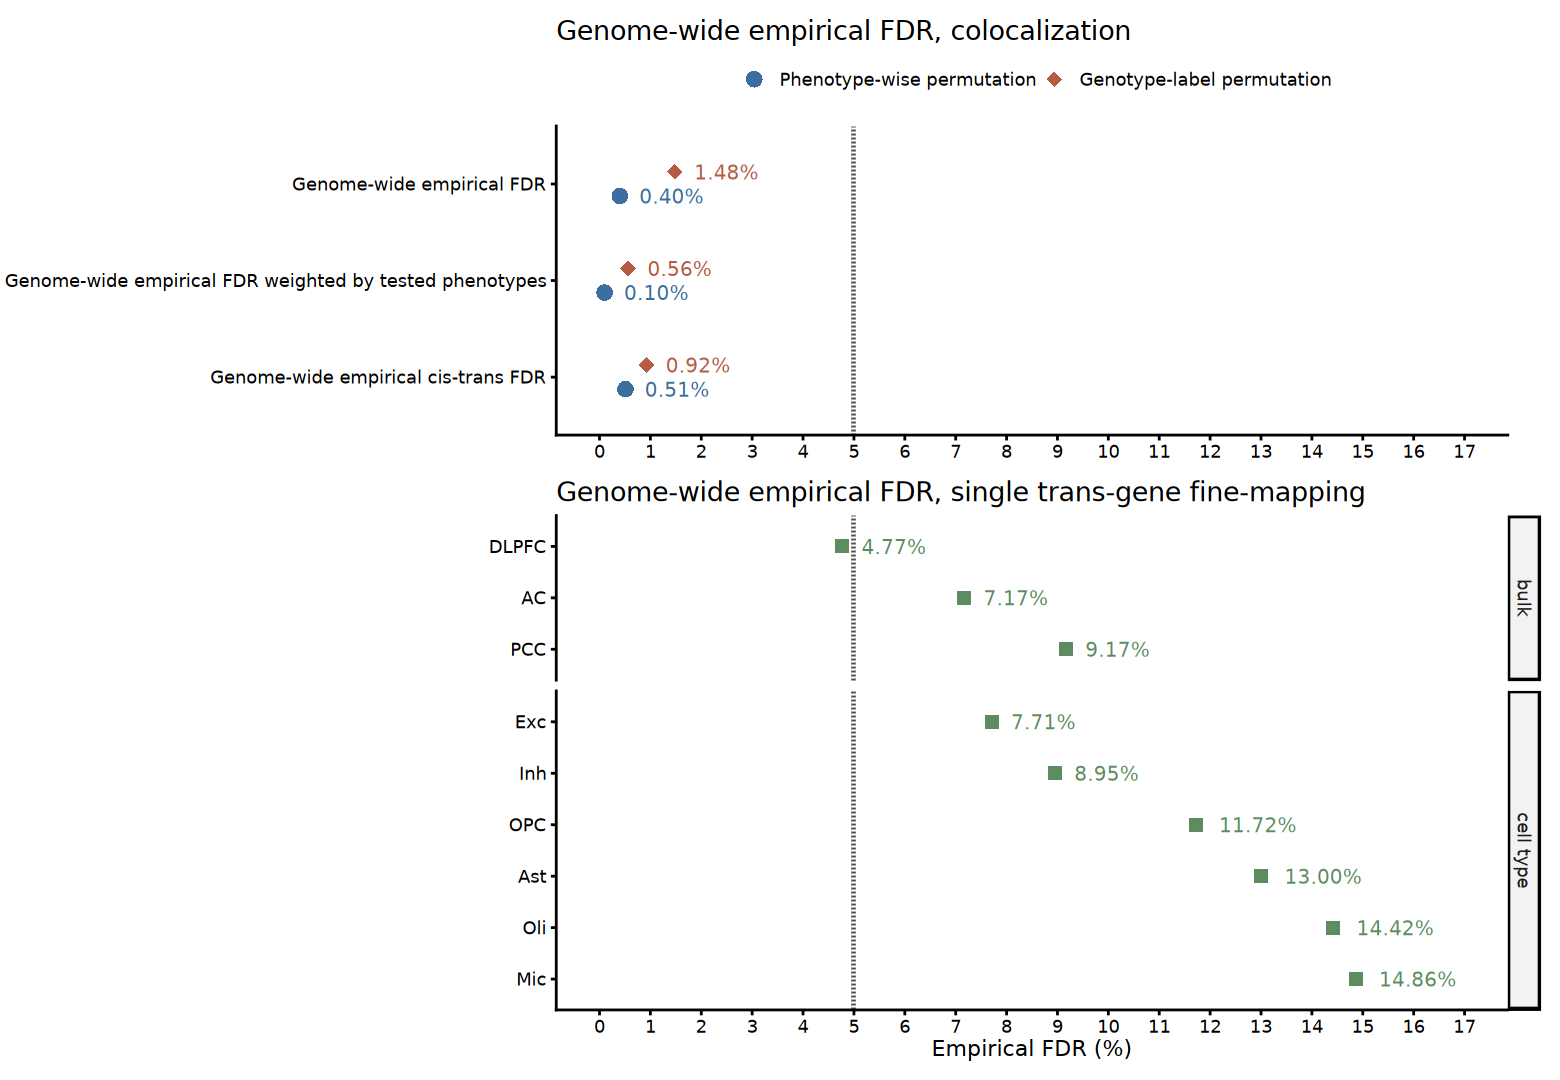

In [2]:
perm_cols <- c("Phenotype-wise permutation" = "#3C6E9F", "Genotype-label permutation" = "#B65C45")
co <- d$colocalization
co$metric <- factor(co$metric, levels = rev(levels(co$metric)))
p1 <- ggplot(co, aes(x = fdr_pct, y = metric, colour = permutation, shape = permutation)) +
  geom_vline(xintercept = 5, linetype = "22", colour = "#555555", linewidth = 1) +
  geom_point(size = 4, position = position_dodge(width = 0.5)) +
  geom_text(aes(label = sprintf("%.2f%%", fdr_pct)), hjust = -0.3, size = 4.2,
            position = position_dodge(width = 0.5), show.legend = FALSE) +
  scale_colour_manual(values = perm_cols, name = NULL) +
  scale_shape_manual(values = c(16, 18), name = NULL) +
  scale_x_continuous(limits = c(0, 17), breaks = 0:17) +
  labs(x = NULL, y = NULL, title = "Genome-wide empirical FDR, colocalization") +
  theme_classic(base_size = 13) + theme(legend.position = "top")

fm <- d$finemapping
fm$context <- factor(fm$context, levels = rev(fm$context))
p2 <- ggplot(fm, aes(x = fdr_pct, y = context)) +
  geom_vline(xintercept = 5, linetype = "22", colour = "#555555", linewidth = 1) +
  geom_point(shape = 15, size = 3.6, colour = "#5E8C61") +
  geom_text(aes(label = sprintf("%.2f%%", fdr_pct)), hjust = -0.3, size = 4.2, colour = "#5E8C61") +
  facet_grid(group ~ ., scales = "free_y", space = "free_y") +
  scale_x_continuous(limits = c(0, 17), breaks = 0:17) +
  labs(x = "Empirical FDR (%)", y = NULL,
       title = "Genome-wide empirical FDR, single trans-gene fine-mapping") +
  theme_classic(base_size = 13) + theme(strip.background = element_rect(fill = "grey95"))
options(repr.plot.width = 13, repr.plot.height = 9)
p1 / p2 + plot_layout(heights = c(1, 1.6))